In [ ]:
pip install tensorflow

In [1]:
import tensorflow as tf
from tensorflow import keras
import random
import matplotlib.pyplot as plt

In [2]:
mnist = tf.keras.datasets.mnist #Importing MNIST datase 
# Splitting it into training and testing data 
(x_train, y_train), (x_test, y_test) = mnist.load_data() 
 
x_train = x_train / 255 
x_test = x_test / 255 


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 8s 1us/step


In [3]:
model = keras.Sequential([ 
keras.layers.Flatten(input_shape=(28, 28)), 
keras.layers.Dense(128, activation="relu"), 
keras.layers.Dense(10,activation="softmax") 
]) 
 
model.summary() 

C:\Users\DELL\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(optimizer="sgd", 
loss="sparse_categorical_crossentropy", 
metrics=['accuracy']) 
 
history=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5) 

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8420 - loss: 0.6344 - val_accuracy: 0.9064 - val_loss: 0.3525
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9069 - loss: 0.3340 - val_accuracy: 0.9199 - val_loss: 0.2906
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9196 - loss: 0.2865 - val_accuracy: 0.9275 - val_loss: 0.2571
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9278 - loss: 0.2573 - val_accuracy: 0.9324 - val_loss: 0.2358
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9336 - loss: 0.2352 - val_accuracy: 0.9376 - val_loss: 0.2177


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9376 - loss: 0.2177
Loss=0.218
Accuracy=0.938


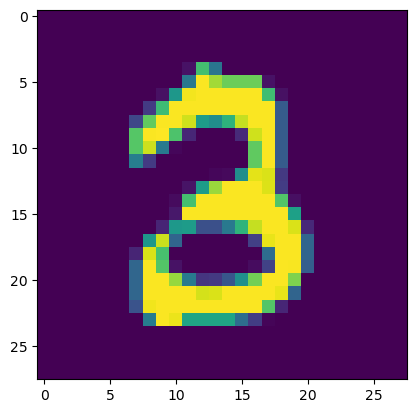

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


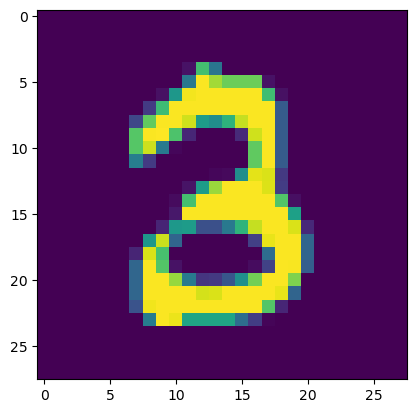

Predicted value:  [2.8358816e-04 7.2937924e-05 1.9914711e-01 6.9295591e-01 7.6631968e-06
 5.9261872e-03 7.1326227e-05 6.0345534e-05 9.9282496e-02 2.1923759e-03]


In [5]:

test_loss,test_acc=model.evaluate(x_test,y_test) 
print("Loss=%.3f" %test_loss) 
print("Accuracy=%.3f" %test_acc) 
n=random.randint(0,9999) 
plt.imshow(x_test[n]) 
plt.show() 
predicted_value=model.predict(x_test) 
plt.imshow(x_test[n]) 
plt.show() 
print('Predicted value: ', predicted_value[n]) 

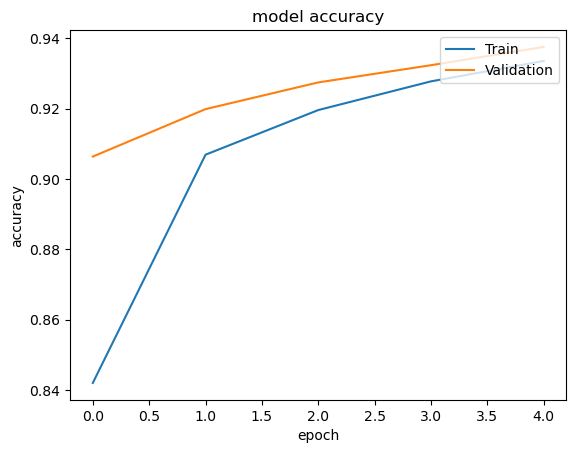

In [6]:
plt.plot(history.history['accuracy']) 
plt.plot(history.history['val_accuracy']) 
plt.title('model accuracy') 
plt.ylabel('accuracy') 
plt.xlabel('epoch') 
plt.legend(['Train', 'Validation'], loc='upper right') 
plt.show()

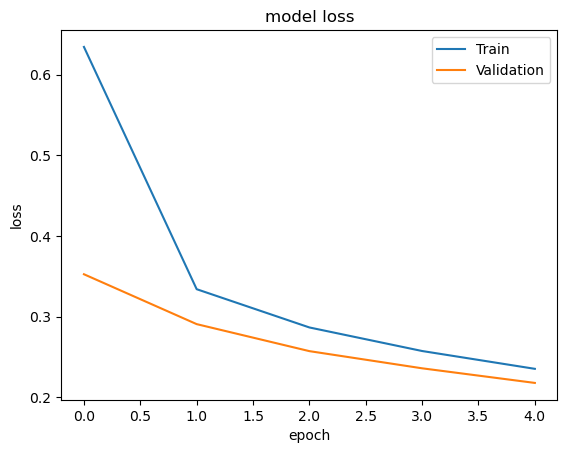

In [7]:
 
plt.plot(history.history['loss']) 
plt.plot(history.history['val_loss']) 
plt.title('model loss') 
plt.ylabel('loss') 
plt.xlabel('epoch') 
plt.legend(['Train', 'Validation'], loc='upper right') 
plt.show()